# P44: lag-0 tooth out of the comb fit's rejection and SNR gate
Regenerates every README figure from `data/` (no pipeline runs). Heavy steps: `p44lib.py` (sweep), `run_scorecards.sh`, `examples.py`.

In [1]:
import sys, json, pickle
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
HERE = Path.cwd()
sys.path.insert(0, str(HERE))
import figures as F
chosen = json.load(open(F.DATA / 'chosen_cutoff.json'))
chosen

{'fullyear': {'target_wrong': 0.034,
  'v8_success': 0.274,
  'cutoff': 1.02,
  'success': 0.272,
  'wrong': 0.032,
  'alias': 0.009},
 'assigned': {'target_wrong': 0.02,
  'v8_success': 0.167,
  'cutoff': 1.0,
  'success': 0.171,
  'wrong': 0.02,
  'alias': 0.002},
 'chosen': 1.02,
 'modes_agree': False}

## Headline: official scorecards vs `_v8`

In [2]:
pd.read_csv(F.DATA / 'summary.csv').round(3)

,set,mode,run,n,success,wrong,alias,none,precision,gained,lost,new_wrong,fixed_wrong
0,dev_medium_clean,fullyear,old,874,0.265,0.024,0.009,0.701,0.889,NaN,NaN,NaN,NaN
1,dev_medium_clean,fullyear,new,874,0.270,0.019,0.008,0.703,0.908,12.0,8.0,2.0,6.0
2,dev_medium_clean,assigned,old,874,0.153,0.030,0.006,0.811,0.812,NaN,NaN,NaN,NaN
3,dev_medium_clean,assigned,new,874,0.154,0.030,0.005,0.811,0.818,5.0,4.0,3.0,3.0
4,dev_medium_b_clean,fullyear,old,1000,0.274,0.034,0.010,0.682,0.862,NaN,NaN,NaN,NaN
5,dev_medium_b_clean,fullyear,new,1000,0.272,0.032,0.009,0.687,0.869,8.0,10.0,4.0,6.0
6,dev_medium_b_clean,assigned,old,1000,0.167,0.020,0.002,0.811,0.884,NaN,NaN,NaN,NaN
7,dev_medium_b_clean,assigned,new,1000,0.168,0.019,0.002,0.811,0.889,7.0,6.0,0.0,1.0


## Cutoff sweep on dev_medium_b_clean (tuning set)
Old (grey) vs new (red) definition; the star is the rule's pick per mode, the square `_v8`. Bottom row: zoom.

             n_success                                                       \
mode          assigned                          fullyear                      
variant local_tol_trim local_tol_trim_l0x local_tol_trim local_tol_trim_l0x   
cutoff                                                                        
0.96               168                173            278                281   
0.98               167                172            274                277   
1.00               167                171            274                276   
1.02               163                168            271                272   
1.04               162                167            269                269   
1.06               161                164            266                263   
1.08               159                161            260                257   

               n_wrong                                                       
mode          assigned                          full

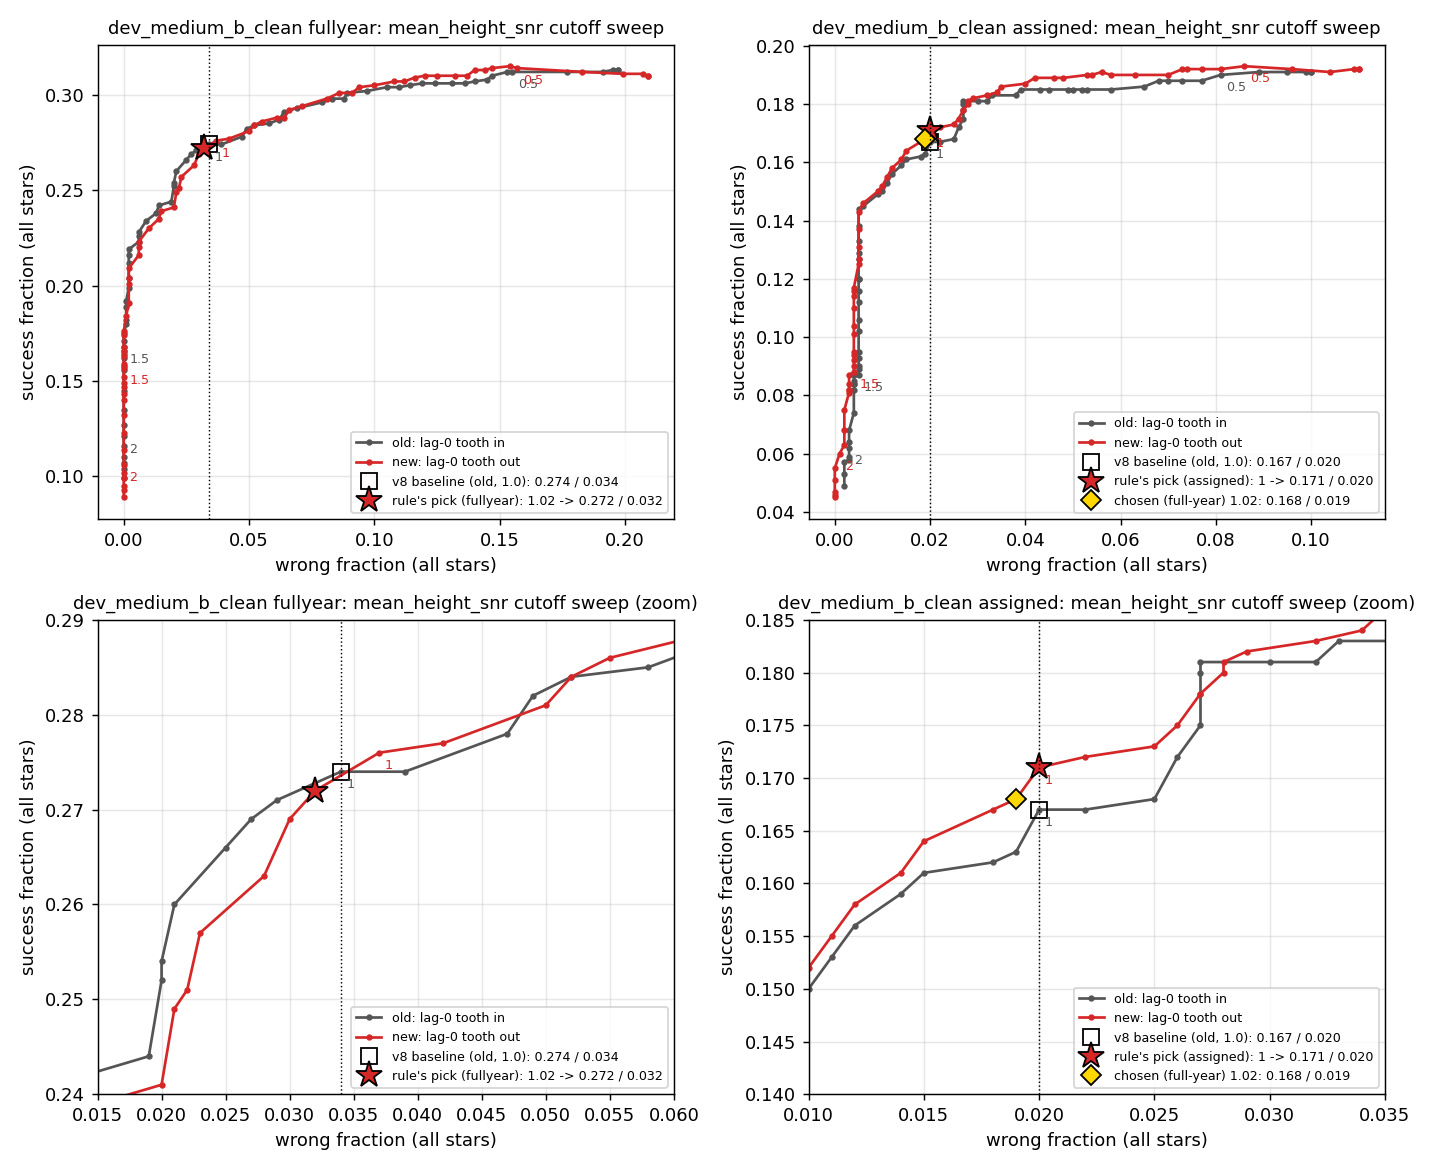

In [3]:
sw = pd.read_csv(F.DATA / 'sweep_B.csv')
print(sw[(sw.cutoff >= 0.96) & (sw.cutoff <= 1.08)].pivot_table(index='cutoff', columns=['mode', 'variant'], values=['n_success', 'n_wrong']).astype(int))
F.fig_sweep(chosen); display(Image(F.FIG / 'fig_sweep.png'))

## `mean_height_snr` (lag-0 tooth out) by candidate class on B
Bottom row: candidates passing every other gate, i.e. those the SNR gate decides.

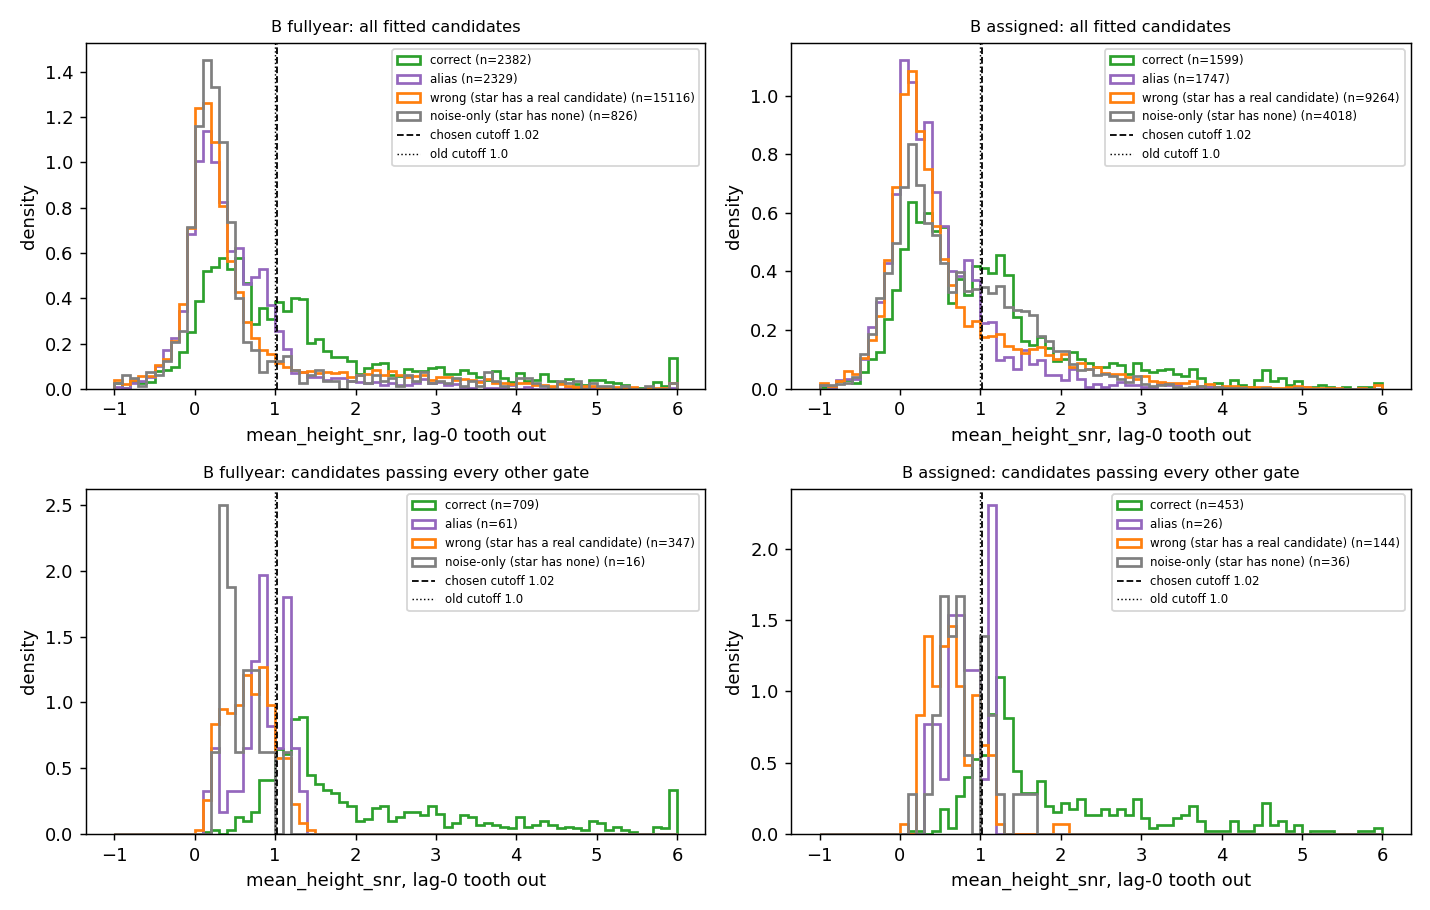

In [4]:
F.fig_snr_hist(chosen); display(Image(F.FIG / 'fig_snr_hist.png'))

## Outcomes by period bin, before/after, both sets and modes (68% Wilson intervals)

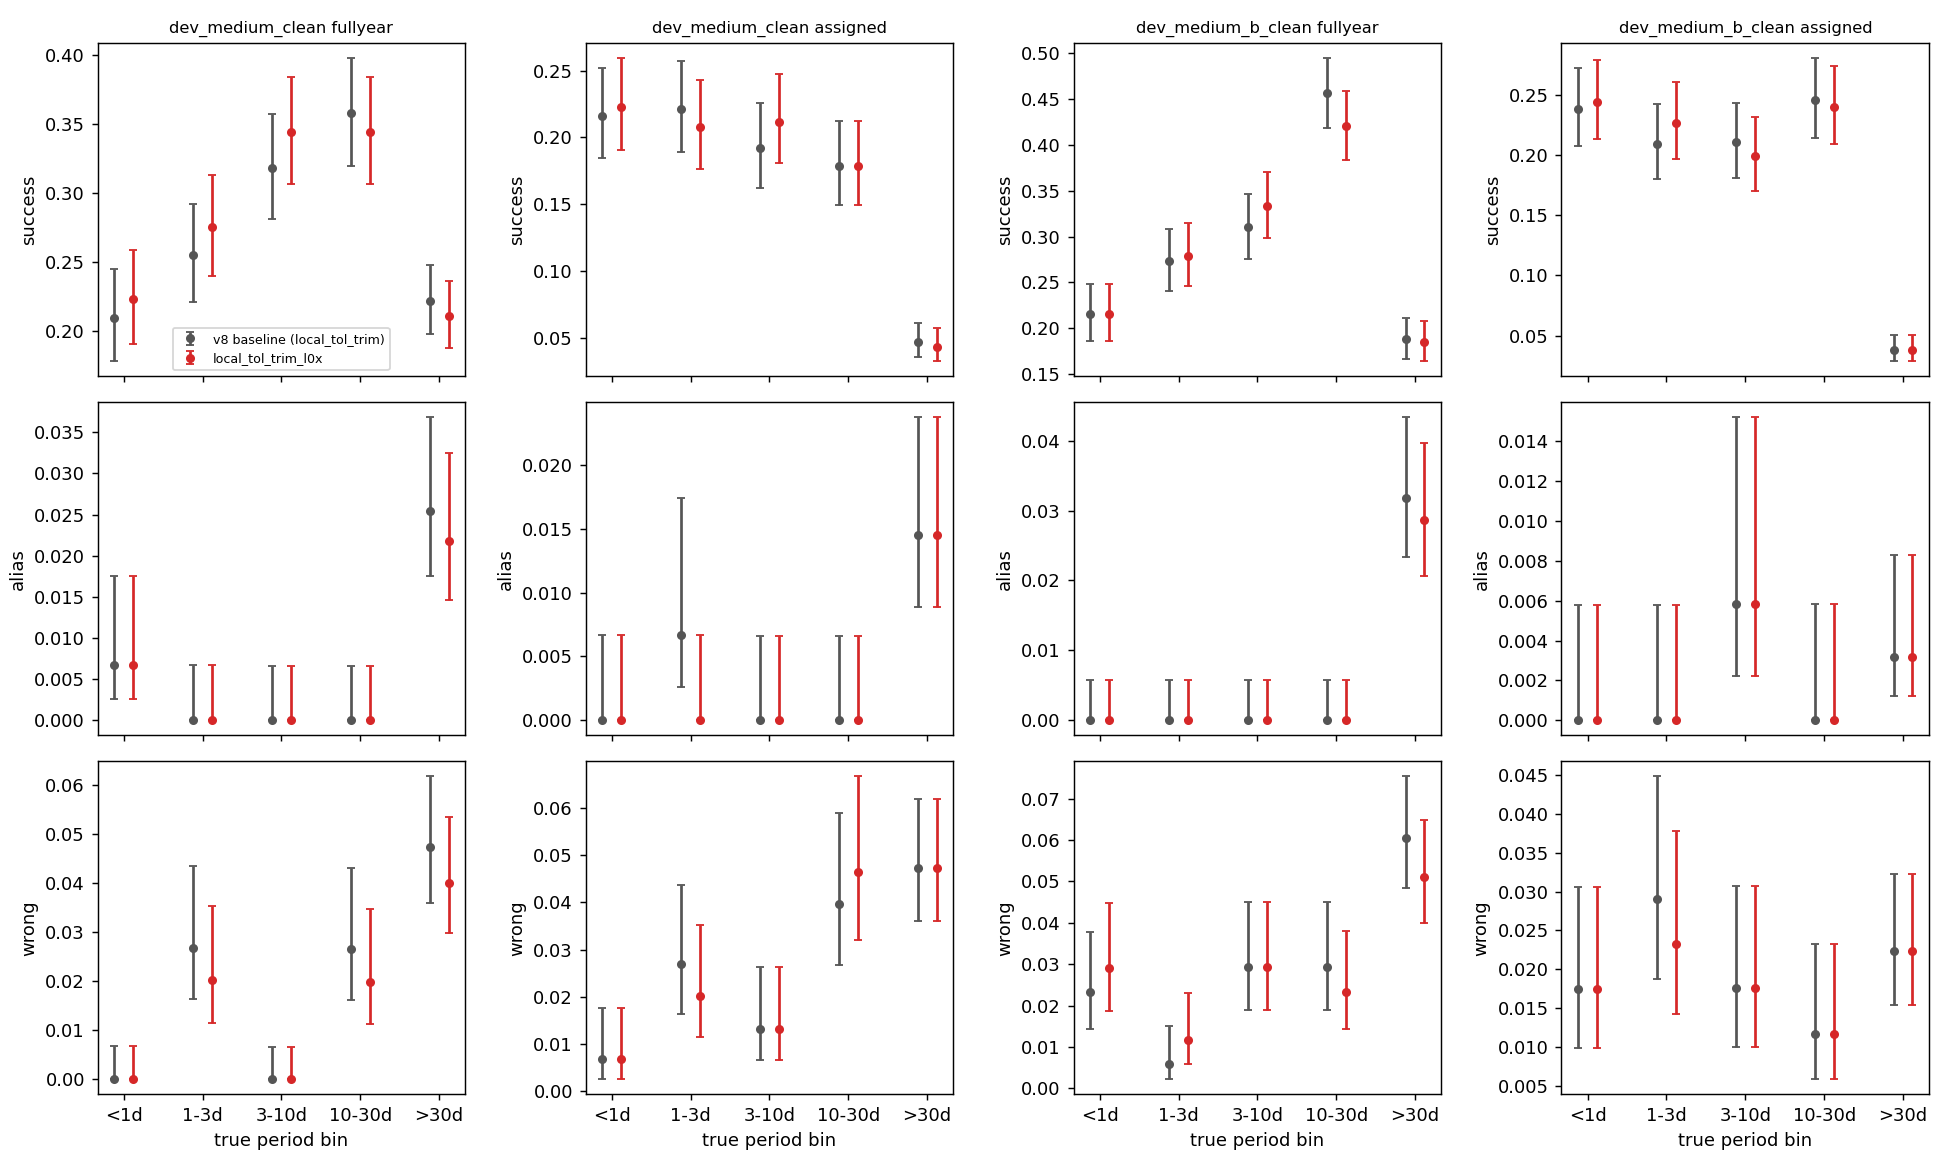

In [5]:
F.fig_bins(); display(Image(F.FIG / 'fig_bins.png'))

## Gate-failure breakdown (closest correct candidate's failed gates)

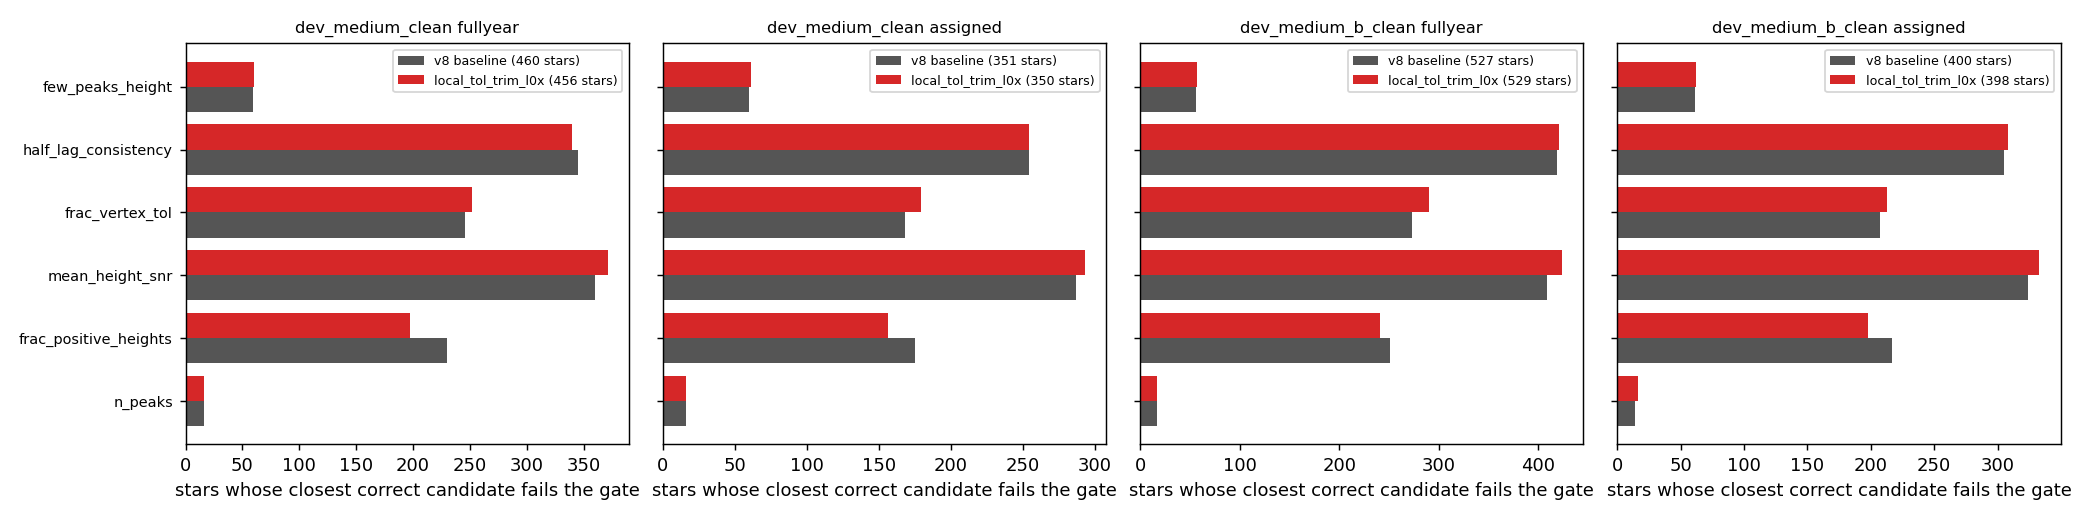

In [6]:
F.fig_gates(); display(Image(F.FIG / 'fig_gates.png'))

## The 13 P43 star-modes lost to the lag-0 tooth

In [7]:
out, l13 = F.summary(); l13

,mode,star_id,true_period,v7,v8,l0x
0,fullyear,smarts-tess-v1.0-015438,2.8651,correct,correct,correct
1,fullyear,smarts-tess-v1.0-026704,4.8744,correct,correct,correct
2,fullyear,smarts-tess-v1.0-046873,8.5139,correct,none,correct
3,fullyear,smarts-tess-v1.0-103059,18.6404,correct,correct,correct
4,fullyear,smarts-tess-v1.0-125098,22.5725,correct,none,none
5,fullyear,smarts-tess-v1.0-157549,28.4289,correct,none,none
6,fullyear,smarts-tess-v1.0-273135,49.2379,correct,none,none
7,fullyear,smarts-tess-v1.0-315124,56.7553,correct,none,none
8,assigned,smarts-tess-v1.0-010328,1.9521,correct,none,none
9,assigned,smarts-tess-v1.0-015438,2.8651,correct,correct,correct


## Examples (judging set, diagnosis only)
Left `_v8`, right l0x; purple = lag-0 tooth, red dotted = 1 σ_ACF.

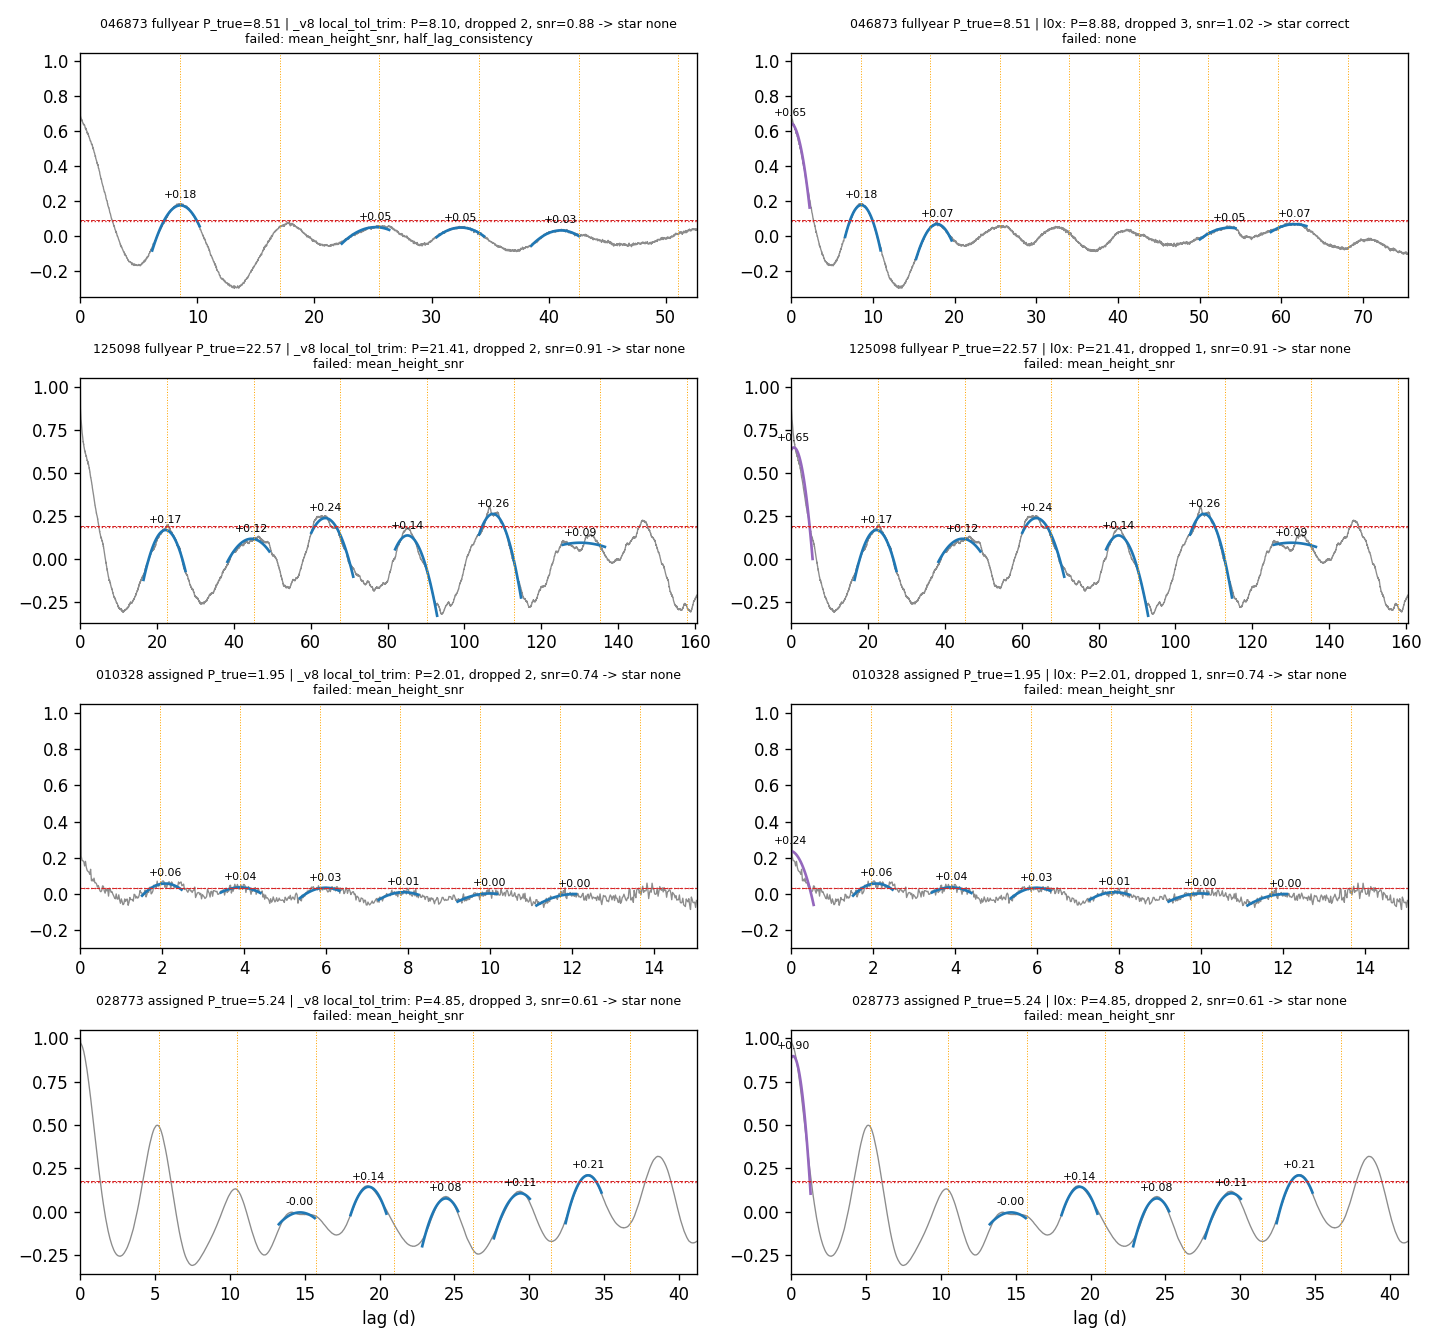

In [8]:
import examples as E
recs = pickle.load(open(F.DATA / 'examples.pkl', 'rb'))
E.plot(recs, F.FIG / 'fig_examples.png'); display(Image(F.FIG / 'fig_examples.png'))